# discotau in three minutes

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/drds1/discotau/blob/main/notebooks/quickstart.ipynb)

A complete accretion-disc fit, start to finish. The data repeat the high signal-to-noise test of the original
CREAM paper (Starkey, Horne & Villforth 2016, MNRAS 456, 1960, their Figure 6): g and i light curves over
100 days, sampled about daily, with signal-to-noise following the lunar phase (about 700 on average). The
true disc has $M\dot M = 10^8\,M_\odot^2\,\mathrm{yr}^{-1}$ around a $10^8\,M_\odot$ black hole, seen at
30 degrees.

`ef.optimise()` then finds the full posterior of the accretion rate and inclination, with the driving light
curve, each band's response and the Bayesian evidence. In the CREAM-paper tests it took a median of 166 s per
fit on one Kaggle CPU over ten simulated drivers, against about 21 minutes for a single NUTS chain. The current
version took 76 s for this fit on a two-core laptop, and the whole notebook just over two minutes. Expect
about a minute more on Colab, for the installation and JAX's first compilation.

For the full tour of `EchoFit`, see [`demo.ipynb`](demo.ipynb).

In [1]:
# On Colab, or anywhere discotau isn't installed yet (about a minute)
import importlib.util

if importlib.util.find_spec("discotau") is None:
    %pip install -q "git+https://github.com/drds1/discotau"

## 1. Simulate the data

A random-walk driver, echoed through the thin-disc response at each band's wavelength, sampled and given
noise as in the CREAM paper. Nothing here is tuned to the fit.

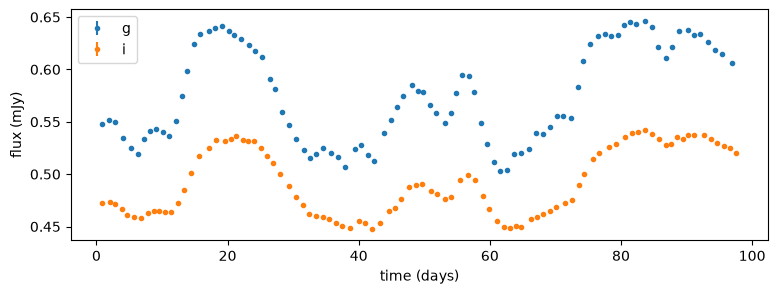

In [2]:
import time

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import discotau.model as model
from discotau import EchoFit
from discotau.forward_model import disk_t1_kelvin, thin_disk_response

M_BH, INCLINATION = 1e8, 30.0
# The paper's M Mdot = 1e8 Msun^2/yr, as discotau's log_mdot (both set the disc temperature T_1 at 1 light-day)
G, MSUN, YR, SIGMA_SB, LD = 6.674e-8, 1.989e33, 3.156e7, 5.6704e-5, 2.998e10 * 86400
T1 = (3 * G * 1e8 * MSUN**2 / YR / (8 * np.pi * SIGMA_SB * LD**3)) ** 0.25
OFFSET = 8.0 - 4 * np.log10(T1 / float(disk_t1_kelvin(0.0, M_BH)))  # log10(M Mdot) = log_mdot + OFFSET
LOG_MDOT = 8.0 - OFFSET

# Wavelength (A), mean AB magnitude, rms (mag), and SNR at dark, half and full Moon (the paper's Tables 2 and 3)
FILTERS = {"g": (4770.0, 17.00, 0.085, (999, 806, 333)), "i": (7545.0, 17.17, 0.069, (930, 776, 364))}

rng = np.random.default_rng(0)
t_grid = np.arange(-30.0, 100.1, 0.1)
df = 0.5 / (t_grid[-1] - t_grid[0])
f = np.arange(df, 10.0, df)  # random-walk power spectrum, P(f) ~ f^-2
phase = 2 * np.pi * np.outer(t_grid, f)
x = np.sin(phase) @ (rng.normal(size=f.size) / f) + np.cos(phase) @ (rng.normal(size=f.size) / f)
x = (x - x.mean()) / x.std()

bands = {}
for name, (wavelength, ab, rms, snrs) in FILTERS.items():
    psi = np.asarray(thin_disk_response(jnp.arange(0.0, 30.0, 0.1), LOG_MDOT, wavelength, INCLINATION, M_BH))
    echo = np.convolve(x, psi / psi.sum())[: t_grid.size][t_grid >= 0]
    flux = 3631e3 * 10 ** (-0.4 * ab) * (1 + rms * np.log(10) / 2.5 * (echo - echo.mean()) / echo.std())
    nrng = np.random.default_rng([0, ord(name), ord("A")])
    t, now = [], 0.0
    while now < 96.8:  # gaps |N(1, 0.2)| days, at least 0.8
        step = abs(nrng.normal(1.0, 0.2))
        if step > 0.8:
            now += step
            t.append(round(now, 1))
    t = np.unique(t)
    f0 = np.interp(t, t_grid[t_grid >= 0], flux)
    yerr = f0 / np.array(snrs, dtype=float)[(np.floor(t / 7).astype(int) + 2) % 3]
    bands[name] = dict(t=t, y=f0 + yerr * nrng.normal(size=t.size), yerr=yerr, wavelength=wavelength)

fig, ax = plt.subplots(figsize=(9, 3))
for name, d in bands.items():
    ax.errorbar(d["t"], d["y"], d["yerr"], fmt=".", label=name)
ax.set(xlabel="time (days)", ylabel="flux (mJy)")
ax.legend();

## 2. Fit

Four lines: the thin-disc response, the black hole mass (fixed), one `add_lightcurve` per band and the frequency
grid. Everything else is the default.

In [3]:
model.response_function = thin_disk_response
ef = EchoFit(M_BH=M_BH)
for name, d in bands.items():
    ef.add_lightcurve(name, wavelength=d["wavelength"], t=d["t"], y=d["y"], yerr=d["yerr"])
ef.build_grid(tau_max=30.0)

start = time.perf_counter()
ef.optimise(rng_seed=0)
print(f"fit took {time.perf_counter() - start:.0f} s")

fit took 76 s


## 3. Results

The paper's own fit (CREAM, 2016) found $\log M\dot M = 8.00 \pm 0.03$.

log M Mdot   8.01 +/- 0.03   (truth 8.00)
inclination  34 (68% 32-35) degrees   (truth 30)
log evidence 791.1,  importance-sampling k_hat -0.28 (below 0.7 is reliable)


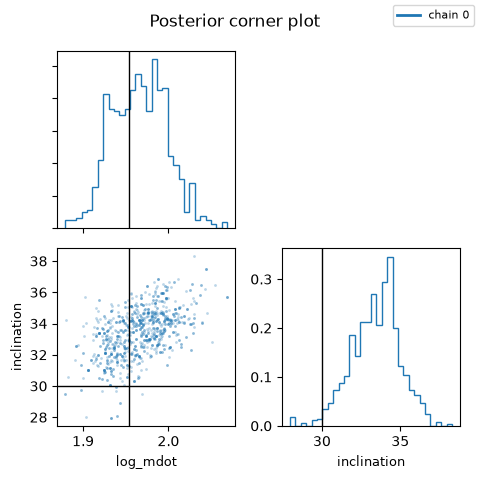

In [4]:
lm = np.asarray(ef.samples["log_mdot"]) + OFFSET
inc = np.asarray(ef.samples["inclination"])
r = ef.nested_laplace_result
print(f"log M Mdot   {lm.mean():.2f} +/- {lm.std():.2f}   (truth 8.00)")
print(f"inclination  {np.median(inc):.0f} (68% {np.percentile(inc, 16):.0f}-{np.percentile(inc, 84):.0f}) degrees   (truth 30)")
print(f"log evidence {ef.log_evidence:.1f},  importance-sampling k_hat {r['k_hat']:.2f} (below 0.7 is reliable)")
ef.plot_corner(true_values={"log_mdot": LOG_MDOT, "inclination": INCLINATION});

The model light curves and responses, with 68 and 95 per cent bands. The first plot after a direct solve
also draws the driver's Fourier amplitudes exactly (the linear parameters integrated out during the fit), so it
takes a little longer than the ones after it.

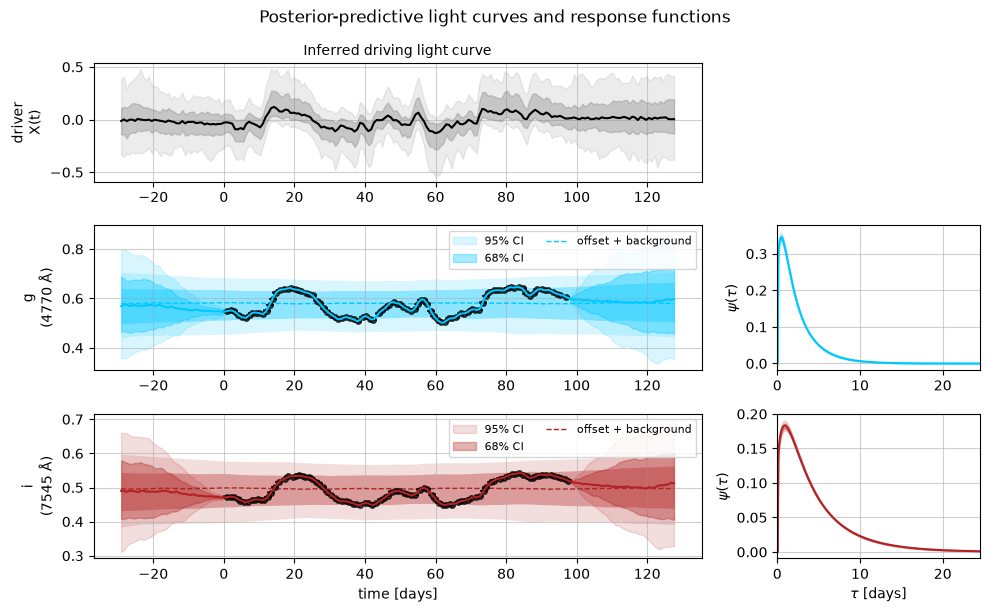

In [5]:
ef.plot_lightcurve_fits();

## Quicker still

`optimise(method="laplace")` describes the posterior with a single Gaussian (about 30 seconds here). That's
enough when the posterior has one mode, as it does on this data set. The default nested solve above
also searches the whole prior range for other modes and corrects the Gaussian by importance sampling, which
is why it is the default.

In [6]:
start = time.perf_counter()
ef.optimise(method="laplace", rng_seed=0)
lm = np.asarray(ef.samples["log_mdot"]) + OFFSET
print(f"{time.perf_counter() - start:.0f} s,  log M Mdot {lm.mean():.2f} +/- {lm.std():.2f}")

12 s,  log M Mdot 8.01 +/- 0.03


/Users/david/projects/datascience_projects/echofit/discotau/echofit.py:1380: UserWarning: optimise(): only 3 of 4 restarts reached the same optimum; restart 3 ended 29 sd away, +200 in potential. The one with the highest Laplace evidence is kept, but the posterior has several optima and this single Gaussian may describe the wrong one: use optimise() (the nested Laplace solve, which searches for every mode) or .fit() with several chains.
  warnings.warn(
